# 01 · Analyse exploratoire (EDA)

**Objectif** : comprendre l'activité de ShopPulse avant de segmenter et de modéliser. Trois axes sont demandés : les distributions, la saisonnalité et la géographie. Le notebook se termine par deux tests statistiques, chacun motivé par une question métier.

Pré-requis : la base doit être chargée par le pipeline (`make db etl`).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
from sqlalchemy import text

from shoppulse.config import FULL_MONTHS
from shoppulse.db import get_engine
from shoppulse.geo import STATE_REGION
from shoppulse.queries import QUERIES_DIR, run_query

engine = get_engine()
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})


def sql(query: str) -> pd.DataFrame:
    with engine.connect() as connection:
        return pd.read_sql(text(query), connection)

## 1. Vue d'ensemble : une ligne par commande

In [2]:
orders = sql("""
    SELECT o.order_id, o.order_status, o.order_purchase_timestamp,
           c.customer_state, v.order_value, r.review_score,
           d.delivery_days, d.is_late
    FROM orders AS o
    JOIN customers AS c USING (customer_id)
    LEFT JOIN (SELECT order_id, sum(price + freight_value) AS order_value
               FROM order_items GROUP BY order_id) AS v USING (order_id)
    LEFT JOIN (SELECT order_id, avg(review_score) AS review_score
               FROM order_reviews GROUP BY order_id) AS r USING (order_id)
    LEFT JOIN delivered_orders AS d USING (order_id)
""")
orders["order_value"] = orders["order_value"].astype(float)
orders["region"] = orders["customer_state"].map(STATE_REGION)
print(
    f"{len(orders):,} commandes du {orders.order_purchase_timestamp.min():%d/%m/%Y} "
    f"au {orders.order_purchase_timestamp.max():%d/%m/%Y}"
)
orders["order_status"].value_counts(normalize=True).mul(100).round(2).to_frame("%")

99,441 commandes du 04/09/2016 au 17/10/2018


,%
order_status,
delivered,97.02
shipped,1.11
canceled,0.63
unavailable,0.61
invoiced,0.32
processing,0.30
created,0.01
approved,0.00


**Lecture** : les données couvrent environ 99 000 commandes, de septembre 2016 à octobre 2018. 97 % des commandes sont livrées. Les autres statuts (annulée, indisponible, en cours…) pèsent moins de 3 %. Pour les analyses de livraison, on ne garde que les commandes livrées, via la vue `delivered_orders`.

## 2. Distributions

,order_value,review_score,delivery_days
count,98666.0,98673.0,96470.0
mean,160.6,4.1,12.5
std,220.5,1.3,9.6
min,9.6,1.0,0.0
25%,62.0,4.0,7.0
50%,105.3,5.0,10.0
75%,176.9,5.0,16.0
max,13664.1,5.0,210.0


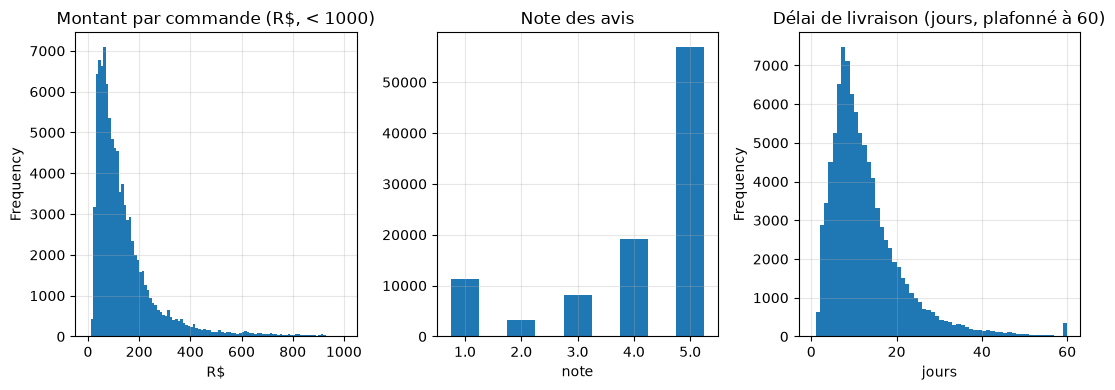

In [3]:
fig, axes = plt.subplots(1, 3)
orders["order_value"].dropna().plot.hist(
    bins=100, ax=axes[0], logx=False, range=(0, 1000)
)
axes[0].set(title="Montant par commande (R$, < 1000)", xlabel="R$")
orders["review_score"].round().value_counts().sort_index().plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Note des avis", xlabel="note")
orders["delivery_days"].dropna().clip(upper=60).plot.hist(bins=60, ax=axes[2])
axes[2].set(title="Délai de livraison (jours, plafonné à 60)", xlabel="jours")
plt.tight_layout()
orders[["order_value", "review_score", "delivery_days"]].describe().round(1)

**Lecture** :

- **Montant** : la distribution est très asymétrique. Le panier médian est de 105 R$ pour une moyenne de 161 R$, et quelques commandes dépassent 10 000 R$. Pour la segmentation, on passera donc les montants au logarithme.
- **Notes** : elles sont polarisées. 5/5 domine, mais 1/5 est la troisième note la plus fréquente, ce qui signale un problème identifiable plutôt qu'une insatisfaction diffuse.
- **Délai** : il faut 10 jours en médiane, avec une longue traîne au-delà de 30 jours. Ce sont ces commandes que le modèle de retard doit repérer.

## 3. Saisonnalité

,month,orders,revenue,revenue_growth_pct
13,2017-11-01,7421,1172191.68,53.3
15,2018-01-01,7187,1101920.01,27.9
17,2018-03-01,7168,1152656.99,17.7


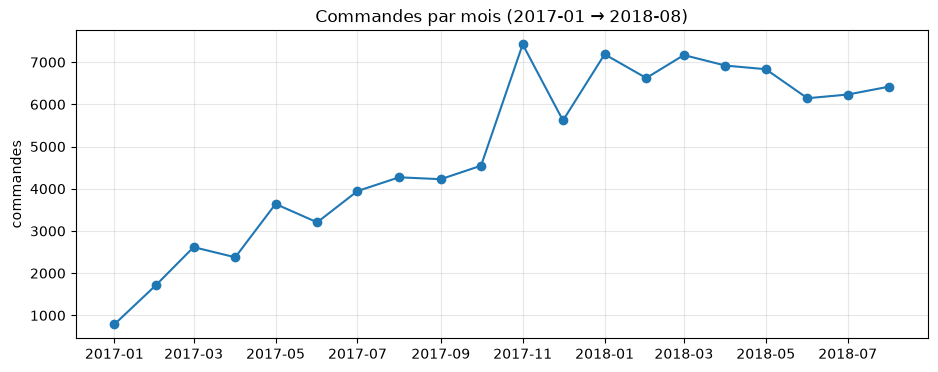

In [4]:
monthly = run_query(QUERIES_DIR / "01_monthly_revenue.sql", engine)
# Les mois de bord sont incomplets : on garde FULL_MONTHS (config partagée).
monthly = monthly[monthly["month"].astype(str).between(*FULL_MONTHS)]
ax = monthly.plot(
    x="month",
    y="orders",
    marker="o",
    legend=False,
    title="Commandes par mois (2017-01 → 2018-08)",
)
ax.set(xlabel="", ylabel="commandes")
monthly.sort_values("orders", ascending=False).head(3)

Part des commandes en semaine : 77%


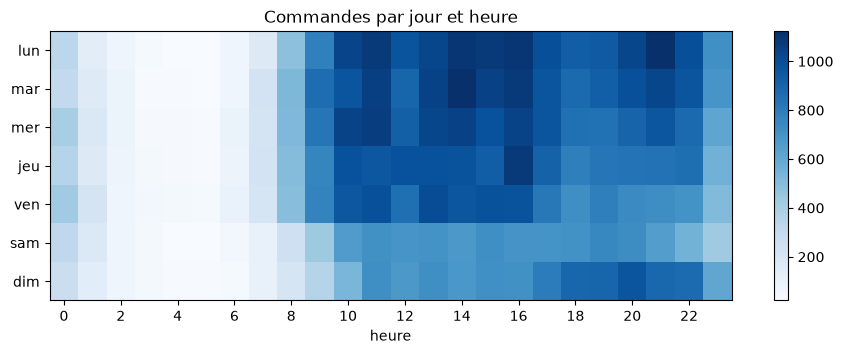

In [5]:
ts = orders["order_purchase_timestamp"]
heat = pd.crosstab(ts.dt.day_of_week, ts.dt.hour)
fig, ax = plt.subplots(figsize=(11, 3.5))
image = ax.imshow(heat, aspect="auto", cmap="Blues")
ax.set(
    yticks=range(7),
    yticklabels=["lun", "mar", "mer", "jeu", "ven", "sam", "dim"],
    xticks=range(0, 24, 2),
    xlabel="heure",
    title="Commandes par jour et heure",
)
ax.grid(False)
fig.colorbar(image, ax=ax)
share_weekday = heat.iloc[:5].sum().sum() / heat.sum().sum()
print(f"Part des commandes en semaine : {share_weekday:.0%}")

**Lecture** :

- **Tendance** : l'activité double courant 2017, puis se stabilise autour de 6 500 à 7 000 commandes par mois en 2018.
- **Pic** : le record est en **novembre 2017** (Black Friday), avec environ 7 400 commandes et +53 % de CA par rapport à octobre. C'est le moment à préparer côté logistique, car le risque de retard y est le plus fort.
- **Rythme hebdomadaire** : on achète surtout en semaine (77 %) et en journée, avec un pic de 10 h à 22 h. Les campagnes marketing gagnent à partir en début de semaine.

## 4. Analyse géographique

SP + RJ + MG = 67% des commandes livrées


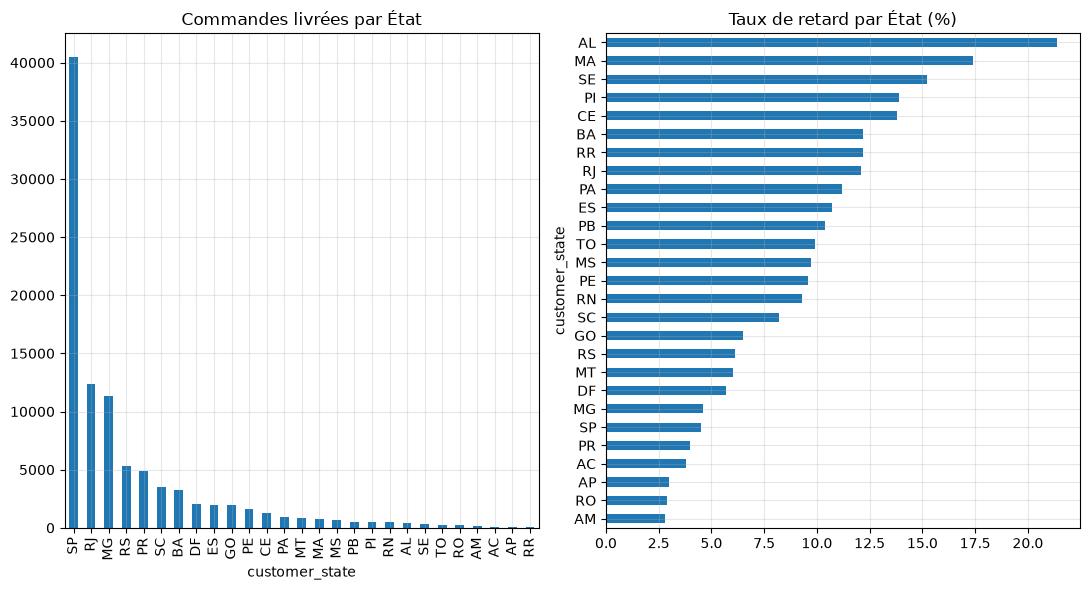

In [6]:
by_state = run_query(QUERIES_DIR / "03_late_rate_by_state.sql", engine)
by_state = by_state.sort_values("delivered_orders", ascending=False)
fig, axes = plt.subplots(1, 2)
by_state.plot.bar(
    x="customer_state",
    y="delivered_orders",
    ax=axes[0],
    legend=False,
    title="Commandes livrées par État",
)
by_state.sort_values("late_rate_pct").plot.barh(
    x="customer_state",
    y="late_rate_pct",
    ax=axes[1],
    legend=False,
    figsize=(11, 6),
    title="Taux de retard par État (%)",
)
plt.tight_layout()
top3 = by_state.head(3)["delivered_orders"].sum() / by_state["delivered_orders"].sum()
print(f"SP + RJ + MG = {top3:.0%} des commandes livrées")

In [7]:
delivered = orders.dropna(subset=["is_late"]).astype({"is_late": bool})
region = delivered.groupby("region").agg(
    commandes=("order_id", "size"),
    retard_pct=("is_late", "mean"),
    delai_moyen_j=("delivery_days", "mean"),
    note_moyenne=("review_score", "mean"),
)
region["retard_pct"] *= 100
region.sort_values("retard_pct").round(1)

,commandes,retard_pct,delai_moyen_j,note_moyenne
region,,,,
Sud,13813,5.9,14.0,4.2
Sudeste,66193,6.1,10.7,4.2
Centre-Ouest,5624,6.5,15.0,4.1
Nord,1796,8.6,22.5,4.0
Nordeste,9044,12.7,19.9,4.0


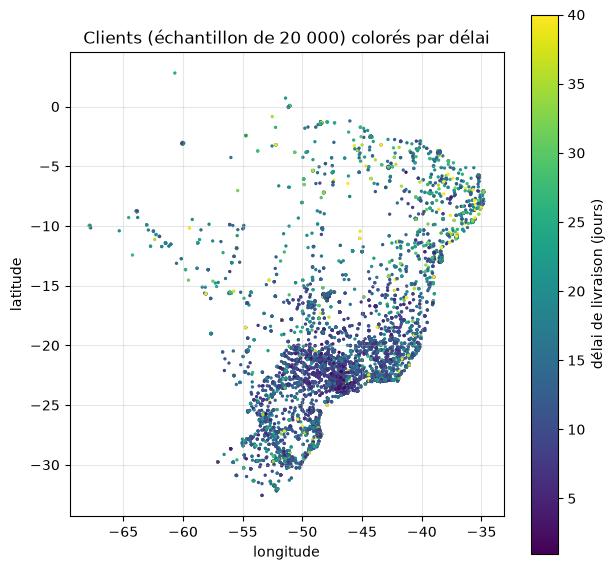

In [8]:
points = sql("""
    SELECT g.geolocation_lat AS lat, g.geolocation_lng AS lng, d.delivery_days
    FROM delivered_orders AS d
    JOIN customers AS c USING (customer_unique_id)
    JOIN geolocation AS g ON g.geolocation_zip_code_prefix = c.customer_zip_code_prefix
    ORDER BY random() LIMIT 20000
""")
fig, ax = plt.subplots(figsize=(7, 7))
scatter = ax.scatter(
    points["lng"],
    points["lat"],
    c=points["delivery_days"].clip(upper=40),
    s=2,
    cmap="viridis",
)
fig.colorbar(scatter, ax=ax, label="délai de livraison (jours)")
ax.set(
    title="Clients (échantillon de 20 000) colorés par délai",
    xlabel="longitude",
    ylabel="latitude",
)
ax.set_aspect("equal")

**Lecture** :

- **Concentration** : SP, RJ et MG font 67 % des commandes, et SP seul en représente plus de 40 %.
- **Inégalités de service** : le délai moyen passe de 11 jours dans le Sudeste à 20-23 jours dans le Nord et le Nordeste. Le taux de retard double dans le Nordeste (12,7 % contre 6 % dans le Sud-Est), et AL et MA dépassent 17 %. La carte montre la même chose : plus on s'éloigne du pôle São Paulo, où se trouve la majorité des vendeurs, plus le délai augmente.
- **Pour la suite** : la distance client-vendeur sera une variable clé du modèle de retard. La région sera aussi l'axe de l'audit d'équité.

## 5. Test 1 : un retard dégrade-t-il la note client ?

**Question métier (Service client)** : faut-il traiter le retard comme une cause directe des avis négatifs ?

- H0 : les notes des commandes en retard et à l'heure ont la même distribution.
- H1 : les notes des commandes en retard sont plus basses.
- **Test de Mann-Whitney U (unilatéral)**. La note est ordinale (1 à 5) et pas du tout normale, donc un test t n'est pas adapté. On mesure l'ampleur de l'écart avec la corrélation rang-bisériale (r).

In [9]:
scored = delivered.dropna(subset=["review_score"])
late = scored.loc[scored["is_late"], "review_score"]
on_time = scored.loc[~scored["is_late"], "review_score"]
u, p_value = stats.mannwhitneyu(late, on_time, alternative="less")
effect = 1 - 2 * u / (len(late) * len(on_time))
print(f"Note moyenne : en retard {late.mean():.2f} vs à l'heure {on_time.mean():.2f}")
print(f"U = {u:,.0f}  p = {p_value:.1e}  r rang-bisériale = {effect:.2f}")

Note moyenne : en retard 2.27 vs à l'heure 4.29
U = 103,308,952  p = 0.0e+00  r rang-bisériale = 0.64


**Conclusion** : on rejette H0 (p ≈ 0). L'effet est **fort** (r ≈ 0,64), avec 2,3/5 en moyenne pour une commande en retard contre 4,3/5 à l'heure. Le retard est le premier levier de satisfaction : prédire le retard, c'est prévenir les avis négatifs. C'est la justification métier du modèle du Lot 4.

*Limite* : ce test montre une association, pas une causalité. Un produit mal emballé peut à la fois arriver en retard et décevoir.

## 6. Test 2 : le risque de retard dépend-il de la région ?

**Question métier (Logistique)** : faut-il des actions logistiques ciblées par région ? La réponse prépare aussi l'audit d'équité du modèle de retard (Lot 4).

- H0 : le fait d'être en retard est indépendant de la région du client.
- **Test du χ² d'indépendance** sur le tableau de contingence région × retard. On mesure l'intensité du lien avec le V de Cramér.

In [10]:
table = pd.crosstab(delivered["region"], delivered["is_late"])
chi2, p_value, dof, _ = stats.chi2_contingency(table)
cramer_v = (chi2 / (table.values.sum() * (min(table.shape) - 1))) ** 0.5
print(f"χ² = {chi2:,.0f}  ddl = {dof}  p = {p_value:.1e}  V de Cramér = {cramer_v:.3f}")
table.assign(retard_pct=lambda t: (100 * t[True] / t.sum(axis=1)).round(1))

χ² = 578  ddl = 4  p = 1.1e-123  V de Cramér = 0.077


is_late,False,True,retard_pct
region,,,
Centre-Ouest,5257,367,6.5
Nord,1642,154,8.6
Nordeste,7894,1150,12.7
Sud,12998,815,5.9
Sudeste,62145,4048,6.1


**Conclusion** : on rejette H0 (p ≈ 10⁻¹²⁰). Le retard dépend bien de la région. Le lien reste **faible** (V ≈ 0,08), car la région n'explique qu'une petite part du retard. L'écart est pourtant opérationnel : un client du Nordeste a 2 fois plus de risques d'être livré en retard qu'un client du Sud.

*Conséquences* :

1. **Logistique** : afficher une date estimée plus réaliste dans le Nord et le Nordeste, ou y développer des vendeurs locaux.
2. **Équité** : un modèle de retard reproduira cet écart. L'audit du Lot 4 devra vérifier que ses erreurs ne pénalisent pas davantage ces régions.

## À retenir

| Constat | Chiffre | Conséquence |
|---|---|---|
| Le retard fait chuter la note | 2,3 contre 4,3 /5 | Modèle de prédiction du retard (Lot 4) |
| Le Nord et le Nordeste sont mal servis | retard × 2, délai × 2 | Audit d'équité par région |
| Le Black Friday est le pic annuel | +53 % de CA en nov. 2017 | Anticiper les stocks et les transporteurs |
| Les clients achètent une seule fois | 97 % n'ont qu'une commande | Segmentation RFM et réachat (notebook 02) |